

# Hospital Queue Waiting-Time Prediction Using Machine Learning

## 1. Project Overview

This project aims to predict the estimated waiting time of patients in a hospital queue using Machine Learning regression algorithms.

## 2. Problem Statement

Patients often experience delays before consulting a doctor. Long waiting times can affect patient satisfaction and hospital operations.

The objective of this project is to develop a Machine Learning model that estimates patient waiting time based on factors such as queue length, available doctors, patient information and hospital workload.

## 3. Project Objectives

- Explore and understand hospital queue data.
- Perform data cleaning and preprocessing.
- Identify useful features that influence waiting time.
- Train and compare multiple regression algorithms.
- Evaluate model performance using regression metrics.
- Identify the best-performing model.



## 4. Importing the Required Libraries

The notebook uses **Pandas** and **NumPy** for data handling, and **Matplotlib** and **Seaborn** for data visualization. These libraries support the data exploration and analysis stages.

In [ ]:
# Import libraries for data manipulation and visualization.
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns



In [ ]:
# Load the hospital queue dataset from the CSV file.
df=pd.read_csv('/content/hospital_queue_prediction_advanced_with_nulls_50000.csv')
df

,patient_id,arrival_datetime,department,service_type,patient_age,patient_gender,patient_race,admission_required,triage_level,priority_label,...,is_weekend,queue_length_at_arrival,available_doctors,staff_on_duty,patients_arrived_last_30min,average_service_time_min,doctors_currently_busy,waiting_time_minutes,consultation_start_datetime,hospital_load_level
0,SYN-012145,2025-01-01 07:02:00,General Practice,Consultation,7.0,M,Two or More Races,True,4.0,Low,...,False,0,2,2,0.0,17.5,1,0.0,2025-01-01 07:02:00.000000,Low
1,SYN-042920,2025-01-01 07:04:00,General Practice,Consultation,16.0,F,Asian,True,2.0,High,...,False,0,2,2,1.0,12.6,2,0.0,2025-01-01 07:04:00.000000,Low
2,SYN-027031,2025-01-01 07:20:00,General Practice,Emergency assessment,39.0,M,White,True,4.0,Low,...,False,0,2,2,2.0,13.9,1,0.0,2025-01-01 07:20:00.000000,Low
3,SYN-015945,2025-01-01 07:31:00,General Practice,Consultation,61.0,M,White,True,5.0,Non-urgent,...,False,0,2,2,3.0,19.1,2,0.0,2025-01-01 07:31:00.000000,Low
4,SYN-024451,2025-01-01 07:46:00,General Practice,Consultation,25.0,F,Asian,False,4.0,Low,...,False,0,2,2,2.0,17.5,2,0.0,2025-01-01 07:46:00.000000,Low
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
49995,SYN-048420,2025-06-29 22:48:00,General Practice,Follow-up,36.0,F,Pacific Islander,False,1.0,Critical,...,True,6,2,2,4.0,15.3,2,48.7,2025-06-29 23:36:39.626501,High
49996,SYN-012247,2025-06-29 23:01:00,Orthopedics,Consultation,74.0,M,White,False,3.0,Moderate,...,True,1,1,1,0.0,17.5,1,58.1,2025-06-29 23:59:04.354549,Moderate
49997,SYN-008548,2025-06-29 23:11:00,General Practice,Follow-up,40.0,M,African American,False,4.0,Low,...,True,3,2,2,1.0,11.5,2,40.9,2025-06-29 23:51:56.650582,Moderate
49998,SYN-003702,2025-06-29 23:16:00,General Practice,Consultation,10.0,F,White,False,4.0,Low,...,True,4,1,2,2.0,19.4,1,42.8,2025-06-29 23:58:45.491804,Critical


## 5. Initial Data Understanding



In [ ]:
# Check the number of rows and columns in the dataset.
df.shape

(50000, 22)

In [ ]:
# Inspect the data type of each column.
df.dtypes

,0
patient_id,object
arrival_datetime,object
department,object
service_type,object
patient_age,float64
patient_gender,object
patient_race,object
admission_required,bool
triage_level,float64
priority_label,object


In [ ]:
df.columns

Index(['patient_id', 'arrival_datetime', 'department', 'service_type',
       'patient_age', 'patient_gender', 'patient_race', 'admission_required',
       'triage_level', 'priority_label', 'day_of_week', 'hour_of_day',
       'is_weekend', 'queue_length_at_arrival', 'available_doctors',
       'staff_on_duty', 'patients_arrived_last_30min',
       'average_service_time_min', 'doctors_currently_busy',
       'waiting_time_minutes', 'consultation_start_datetime',
       'hospital_load_level'],
      dtype='object')

In [ ]:
df.head()

,patient_id,arrival_datetime,department,service_type,patient_age,patient_gender,patient_race,admission_required,triage_level,priority_label,...,is_weekend,queue_length_at_arrival,available_doctors,staff_on_duty,patients_arrived_last_30min,average_service_time_min,doctors_currently_busy,waiting_time_minutes,consultation_start_datetime,hospital_load_level
0,SYN-012145,2025-01-01 07:02:00,General Practice,Consultation,7.0,M,Two or More Races,True,4.0,Low,...,False,0,2,2,0.0,17.5,1,0.0,2025-01-01 07:02:00.000000,Low
1,SYN-042920,2025-01-01 07:04:00,General Practice,Consultation,16.0,F,Asian,True,2.0,High,...,False,0,2,2,1.0,12.6,2,0.0,2025-01-01 07:04:00.000000,Low
2,SYN-027031,2025-01-01 07:20:00,General Practice,Emergency assessment,39.0,M,White,True,4.0,Low,...,False,0,2,2,2.0,13.9,1,0.0,2025-01-01 07:20:00.000000,Low
3,SYN-015945,2025-01-01 07:31:00,General Practice,Consultation,61.0,M,White,True,5.0,Non-urgent,...,False,0,2,2,3.0,19.1,2,0.0,2025-01-01 07:31:00.000000,Low
4,SYN-024451,2025-01-01 07:46:00,General Practice,Consultation,25.0,F,Asian,False,4.0,Low,...,False,0,2,2,2.0,17.5,2,0.0,2025-01-01 07:46:00.000000,Low


In [ ]:
df.tail()

,patient_id,arrival_datetime,department,service_type,patient_age,patient_gender,patient_race,admission_required,triage_level,priority_label,...,is_weekend,queue_length_at_arrival,available_doctors,staff_on_duty,patients_arrived_last_30min,average_service_time_min,doctors_currently_busy,waiting_time_minutes,consultation_start_datetime,hospital_load_level
49995,SYN-048420,2025-06-29 22:48:00,General Practice,Follow-up,36.0,F,Pacific Islander,False,1.0,Critical,...,True,6,2,2,4.0,15.3,2,48.7,2025-06-29 23:36:39.626501,High
49996,SYN-012247,2025-06-29 23:01:00,Orthopedics,Consultation,74.0,M,White,False,3.0,Moderate,...,True,1,1,1,0.0,17.5,1,58.1,2025-06-29 23:59:04.354549,Moderate
49997,SYN-008548,2025-06-29 23:11:00,General Practice,Follow-up,40.0,M,African American,False,4.0,Low,...,True,3,2,2,1.0,11.5,2,40.9,2025-06-29 23:51:56.650582,Moderate
49998,SYN-003702,2025-06-29 23:16:00,General Practice,Consultation,10.0,F,White,False,4.0,Low,...,True,4,1,2,2.0,19.4,1,42.8,2025-06-29 23:58:45.491804,Critical
49999,SYN-011303,2025-06-29 23:19:00,General Practice,Consultation,22.0,F,White,False,3.0,Moderate,...,True,4,2,2,2.0,27.2,2,0.0,2025-06-29 23:19:00.000000,High


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 22 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   patient_id                   50000 non-null  object 
 1   arrival_datetime             50000 non-null  object 
 2   department                   49750 non-null  object 
 3   service_type                 50000 non-null  object 
 4   patient_age                  49000 non-null  float64
 5   patient_gender               50000 non-null  object 
 6   patient_race                 50000 non-null  object 
 7   admission_required           50000 non-null  bool   
 8   triage_level                 49750 non-null  float64
 9   priority_label               50000 non-null  object 
 10  day_of_week                  50000 non-null  object 
 11  hour_of_day                  50000 non-null  int64  
 12  is_weekend                   50000 non-null  bool   
 13  queue_length_at_

In [ ]:
# returns the statastical data
df.describe()

,patient_age,triage_level,hour_of_day,queue_length_at_arrival,available_doctors,staff_on_duty,patients_arrived_last_30min,average_service_time_min,doctors_currently_busy,waiting_time_minutes
count,49000.000000,49750.000000,50000.000000,50000.000000,50000.000000,50000.000000,49500.000000,49000.000000,50000.000000,50000.000000
mean,39.873939,3.410332,15.045360,4.324280,2.267700,2.375760,6.206889,20.135094,2.180700,17.496038
std,22.717517,1.013244,4.161054,4.857171,0.715351,0.669159,4.315785,11.107595,0.774325,22.505048
min,1.000000,1.000000,7.000000,0.000000,1.000000,1.000000,0.000000,7.000000,1.000000,0.000000
25%,20.000000,3.000000,11.000000,0.000000,2.000000,2.000000,2.000000,11.900000,2.000000,0.000000
50%,39.000000,3.000000,15.000000,3.000000,2.000000,2.000000,6.000000,17.700000,2.000000,9.600000
75%,59.000000,4.000000,19.000000,7.000000,3.000000,3.000000,9.000000,25.600000,3.000000,27.600000
max,79.000000,5.000000,23.000000,35.000000,4.000000,4.000000,27.000000,100.000000,4.000000,190.000000


In [ ]:
df.describe(include=object)

,patient_id,arrival_datetime,department,service_type,patient_gender,patient_race,priority_label,day_of_week,consultation_start_datetime,hospital_load_level
count,50000,50000,49750,50000,50000,50000,50000,50000,50000,50000
unique,50000,42865,7,3,3,7,5,7,49037,4
top,SYN-012145,2025-01-19 10:22:00,General Practice,Consultation,M,White,Moderate,Friday,2025-06-24 19:54:00.000000,Low
freq,1,5,39198,30977,25369,13934,19032,7298,3,18629


### Checking Data Quality

We check for duplicate rows and missing values. These checks help identify data-quality issues that may affect model training.

In [ ]:
# Count duplicate records.
df.duplicated().sum()

np.int64(0)

In [ ]:
# Count missing values in each column.
df.isnull().sum()

,0
patient_id,0
arrival_datetime,0
department,250
service_type,0
patient_age,1000
patient_gender,0
patient_race,0
admission_required,0
triage_level,250
priority_label,0


### Understanding the Target Variable



In [ ]:
df['waiting_time_minutes'].describe()

,waiting_time_minutes
count,50000.000000
mean,17.496038
std,22.505048
min,0.000000
25%,0.000000
50%,9.600000
75%,27.600000
max,190.000000


## 6. Exploratory Data Analysis (EDA)

EDA uses visualizations to understand patterns in the data before building a model.

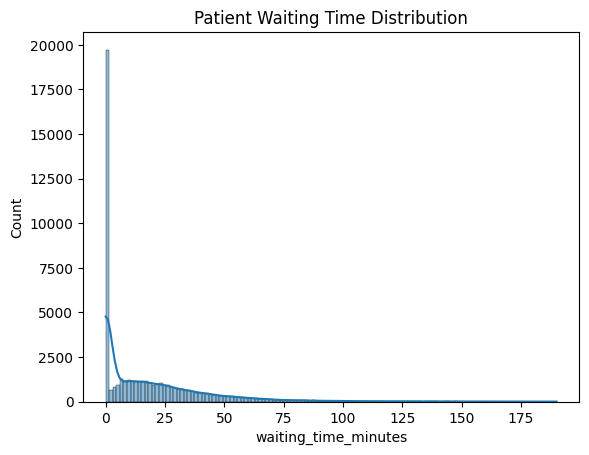

In [ ]:
# We use a histogram to understand the distribution of patient waiting times.
# It helps us identify the most common waiting-time range and understand how waiting times are spread across patients.
sns.histplot(
    data=df,
    x="waiting_time_minutes",
    kde=True)

plt.title("Patient Waiting Time Distribution")
plt.show()

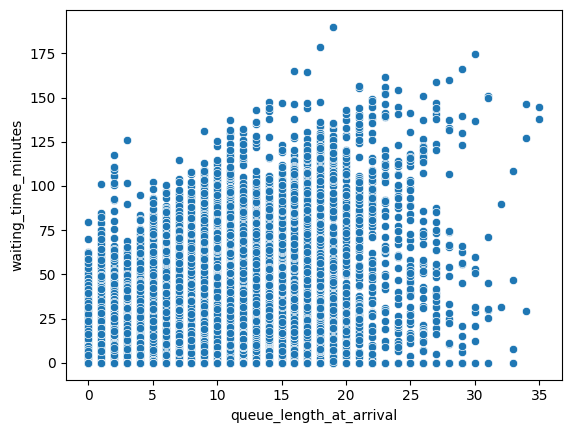

In [ ]:
# sns.scatterplot() is used to understand the relationship between two numerical variables.

sns.scatterplot(data=df,
                x='queue_length_at_arrival',
                y='waiting_time_minutes')
plt.show()

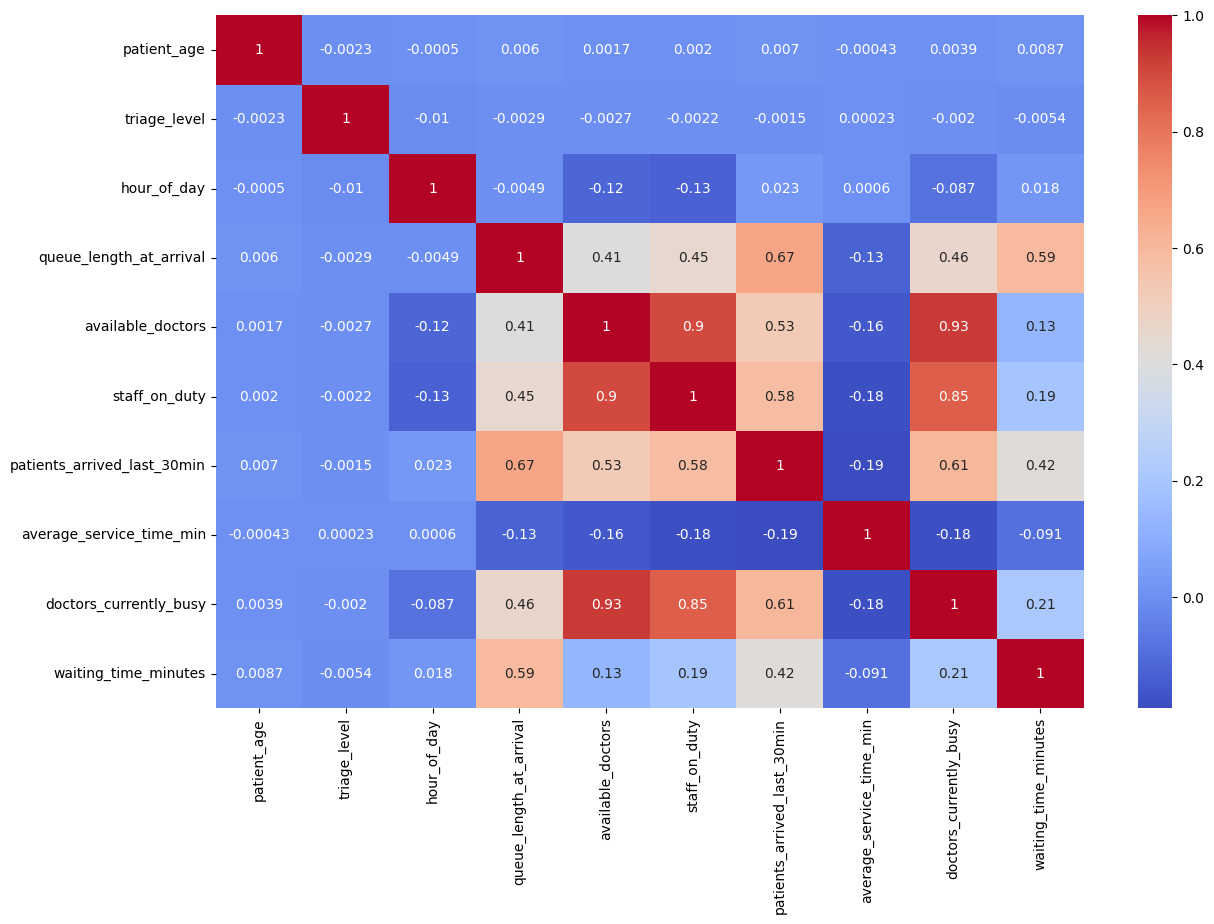

In [ ]:
# Correlation Heatmap is used to visualize the correlation between numerical variables

plt.figure(figsize=(14,9))

sns.heatmap(
    df.select_dtypes(include="number").corr(),
    annot=True,
    cmap="coolwarm"
)

plt.show()

In [ ]:
# Count missing values in each column.
df.isnull().sum()

,0
patient_id,0
arrival_datetime,0
department,250
service_type,0
patient_age,1000
patient_gender,0
patient_race,0
admission_required,0
triage_level,250
priority_label,0


### Filling Missing Triage Levels

A mapping converts the priority categories into numerical triage levels. The mapped value is used to fill missing entries in `triage_level`. This uses the available `priority_label` information rather than assigning an arbitrary value.

fill missing values in triage_level is using priority_label.

In [ ]:
# Map triage priority labels to their corresponding numerical levels.
mapping={
    'Critical':1,
    'High':2,
    'Moderate':3,
    'Low':4,
    'Non-urgent':5

}

df['triage_level']=df['triage_level'].fillna(df['priority_label'].map(mapping))

In [ ]:
# Count missing values in each column.
df.isnull().sum()

,0
patient_id,0
arrival_datetime,0
department,250
service_type,0
patient_age,1000
patient_gender,0
patient_race,0
admission_required,0
triage_level,0
priority_label,0


## 7. Checking Inconsistent Values

The following loop prints the unique values in each column. This helps inspect categories, spot unexpected labels, and identify possible inconsistencies in the dataset.

checking for inconsistent values

In [ ]:
# Inspect unique values in every column to check for inconsistencies.
for i in df.columns:
  print(i)
  print(df[i].unique())
  print('*'*50)

patient_id
['SYN-012145' 'SYN-042920' 'SYN-027031' ... 'SYN-008548' 'SYN-003702'
 'SYN-011303']
**************************************************
arrival_datetime
['2025-01-01 07:02:00' '2025-01-01 07:04:00' '2025-01-01 07:20:00' ...
 '2025-06-29 23:11:00' '2025-06-29 23:16:00' '2025-06-29 23:19:00']
**************************************************
department
['General Practice' 'Orthopedics' 'Cardiology' 'Physiotherapy'
 'Gastroenterology' nan 'Neurology' 'Renal']
**************************************************
service_type
['Consultation' 'Emergency assessment' 'Follow-up']
**************************************************
patient_age
[ 7. 16. 39. 61. 25. 65. 44. 63. 43. 79. 47. 38. 27. 67.  2. 46. 45. 50.
 41. 72. 34. 31. 32. 55. 56. 22. 40. nan 73. 29. 13. 57. 76. 78. 21. 68.
 54. 35. 37. 48. 33. 18. 49. 75. 20. 58.  3. 77. 36. 14. 30. 51. 59. 53.
  1. 11. 26. 28. 69. 12. 74.  6. 71. 66. 70. 52. 42. 17. 15. 64. 19. 24.
  8.  4.  9. 23. 10.  5. 60. 62.]
**********************

## 8. Outlier Analysis

The Interquartile Range (IQR) method is used to count potential outliers in selected numerical columns. Values below Q1 − 1.5 × IQR or above Q3 + 1.5 × IQR are flagged. Box plots provide a visual view of the same numerical features. These are diagnostic checks; the code does not remove the flagged observations.

Oulier Analysis

In [ ]:
# Identify potential outliers using the IQR method.
numeric=['patient_age',
         'queue_length_at_arrival',
         'patients_arrived_last_30min',
         'average_service_time_min',
         'waiting_time_minutes']

for col in numeric:
  Q1=df[col].quantile(0.25)
  Q3=df[col].quantile(0.75)


  IQR=Q3-Q1

  lower=Q1 - 1.5 * IQR
  upper=Q3 + 1.5 * IQR

  outliers=df[
      (df[col]<lower) | (df[col]>upper)
  ]

  print(col,":",len(outliers))

patient_age : 0
queue_length_at_arrival : 1147
patients_arrived_last_30min : 63
average_service_time_min : 1509
waiting_time_minutes : 1804


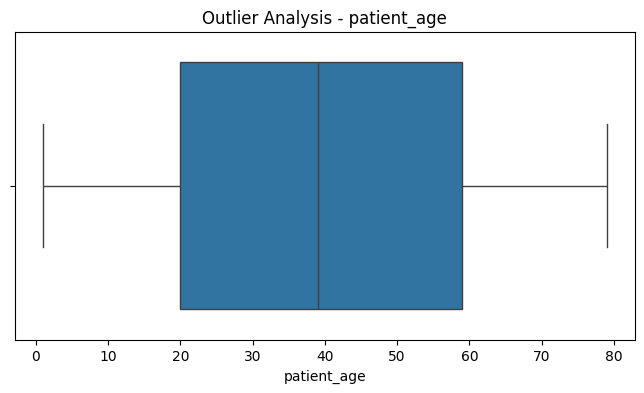

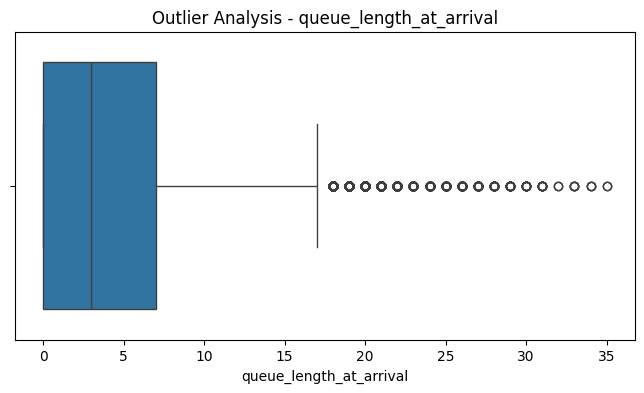

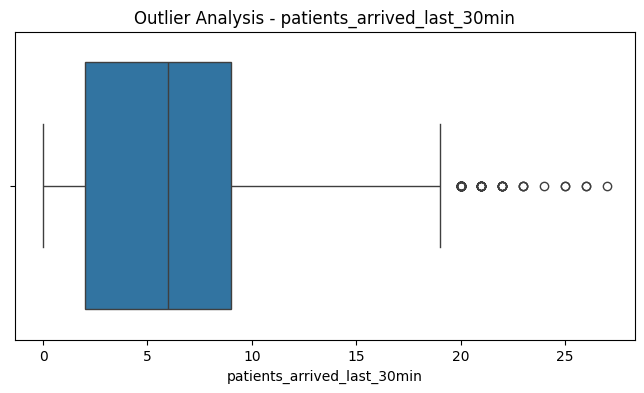

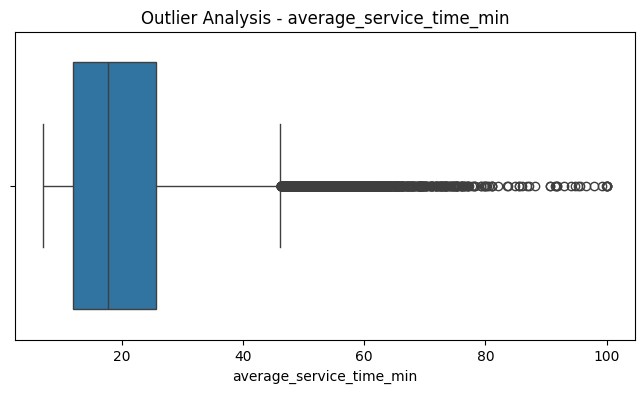

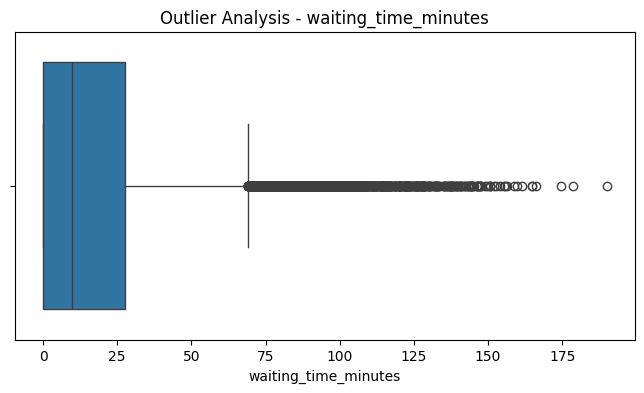

In [ ]:
for col in numeric:
  plt.figure(figsize=(8,4))

  sns.boxplot(x=df[col])

  plt.title("Outlier Analysis - "+ col)

  plt.show()

We performed outlier analysis using box plots and the IQR method. However, we decided not to remove the outliers because these extreme values may represent genuine hospital conditions. Removing them could lead to information loss and make our dataset less representative.

## 9. Feature Engineering

The arrival timestamp is converted to a datetime data type. New time-based features are then extracted, including arrival hour, day of month, day of week, and a weekend indicator. Additional workload features estimate the queue per available doctor and the proportion of doctors currently busy.

In [ ]:
# Convert arrival timestamps into datetime format.
df['arrival_datetime']=pd.to_datetime(df['arrival_datetime'])
df["arrival_datetime"].dtype

dtype('<M8[ns]')

In [ ]:
# Extract date/time information and create workload-related features.
df["arrival_hour"] = df["arrival_datetime"].dt.hour

df["arrival_day"] = df["arrival_datetime"].dt.day

df["arrival_dayofweek"] = df["arrival_datetime"].dt.dayofweek

df["is_weekend"] = (
    df["arrival_dayofweek"] >= 5
).astype(int)

In [ ]:
df["queue_per_doctor"] = (
    df["queue_length_at_arrival"] /
    df["available_doctors"].clip(lower=1)
)

df["busy_doctor_ratio"] = (
    df["doctors_currently_busy"] /
    df["staff_on_duty"].clip(lower=1)
)



### Final Data Checks and Chronological Ordering

Missing values are checked after feature creation. The records are then sorted by arrival time so the later train-test split can preserve chronological order.

In [ ]:
# Count missing values in each column.
df.isnull().sum()

,0
patient_id,0
arrival_datetime,0
department,250
service_type,0
patient_age,1000
patient_gender,0
patient_race,0
admission_required,0
triage_level,0
priority_label,0


we are delaying the filling until the preprocessing stage to prevent data leakage.

In [ ]:
df = df.sort_values(
    "arrival_datetime"
).reset_index(drop=True)

## 10. Selecting Features and Target

The target variable `y` contains `waiting_time_minutes`. The input features `x` contain the information used to predict it. Identifier and selected columns are excluded from the inputs, including timestamps and fields not used as predictors in this notebook.

In [ ]:
# Separate input features from the target and exclude selected columns.
x = df.drop(columns=[
    "waiting_time_minutes",
    "patient_id",
    "consultation_start_datetime",
    "arrival_datetime",
    "priority_label",
    "patient_race",
    "patient_gender",
    "admission_required"
])

y = df["waiting_time_minutes"]

print("X shape:", x.shape)
print("y shape:", y.shape)

X shape: (50000, 19)
y shape: (50000,)


## 11. Train-Test Split

The data is split chronologically: the first 80% of records are used for training and the remaining 20% for testing. Keeping the time order is useful for a time-dependent queue prediction task because the test set represents later records than the training set.

In [ ]:
# Split chronologically: 80% for training and 20% for testing.
split_point = int(len(df) * 0.80)

xtrain = x.iloc[:split_point]
xtest = x.iloc[split_point:]

ytrain = y.iloc[:split_point]
ytest = y.iloc[split_point:]

print("Training data:", xtrain.shape)
print("Testing data:", xtest.shape)

Training data: (40000, 19)
Testing data: (10000, 19)


In [ ]:
print(xtrain.shape)
print(xtest.shape)
print(ytrain.shape)
print(ytest.shape)

(40000, 19)
(10000, 19)
(40000,)
(10000,)


## 12. Preprocessing Pipeline

The preprocessing steps are defined separately for numerical and categorical features:

- Numerical columns: missing values are filled using the median, then values are standardized.
- Categorical columns: missing values are filled using the most frequent category, then categories are converted into numerical indicator columns using one-hot encoding.

A `ColumnTransformer` combines both pipelines. This preprocessing is included in the model pipeline so the same transformations are applied consistently during training and prediction.

In [ ]:
# Define preprocessing for numerical and categorical columns.
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

# Identify numerical and categorical columns
numeric_features = xtrain.select_dtypes(
    include=np.number
).columns

categorical_features = xtrain.select_dtypes(
    include=["object", "category"]
).columns

# Numerical preprocessing
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Categorical preprocessing
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Combine both
preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features)
])

## 13. Training and Comparing Regression Models

Four regression algorithms are evaluated: Linear Regression, Decision Tree, Random Forest, and K-Nearest Neighbors (KNN). Each model is combined with the preprocessing pipeline and trained using the training data.

The test predictions are evaluated using:

- **MAE:** average absolute prediction error, in minutes. Lower is better.
- **MSE:** average squared prediction error. Lower is better and larger errors receive more weight.
- **RMSE:** square root of MSE, expressed in the target's unit (minutes). Lower is better.
- **R² score:** indicates how much variation in waiting time is explained by the model; values closer to 1 generally indicate a better fit.

The results are sorted by MAE to make model comparison easier.

In [ ]:
# Define, train, and evaluate the regression models.

from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.neighbors import KNeighborsRegressor

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

models = {
    "Linear Regression": LinearRegression(),

    "Decision Tree": DecisionTreeRegressor(
        max_depth=12,
        random_state=42
    ),

    "Random Forest": RandomForestRegressor(
        n_estimators=100,
        max_depth=15,
        random_state=42,
        n_jobs=-1
    ),

    "KNN": KNeighborsRegressor(
        n_neighbors=5
    )
}

trained_models = {}
results = []

for name, algorithm in models.items():

    model = Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("regressor", algorithm)
    ])

    model.fit(xtrain, ytrain)

    ypred = model.predict(xtest)

    mae = mean_absolute_error(ytest, ypred)

    mse = mean_squared_error(ytest, ypred)

    rmse = np.sqrt(mse)

    r2 = r2_score(ytest, ypred)

    trained_models[name] = model

    results.append({
        "Model": name,
        "MAE": mae,
        "MSE": mse,
        "RMSE": rmse,
        "R2 Score": r2
    })

results_df = pd.DataFrame(results)

results_df = results_df.sort_values("MAE")

display(results_df)

,Model,MAE,MSE,RMSE,R2 Score
2,Random Forest,10.962194,287.772844,16.963869,0.433325
1,Decision Tree,11.440720,330.211942,18.171735,0.349755
3,KNN,12.001646,340.754095,18.459526,0.328995
0,Linear Regression,12.208026,308.253817,17.557159,0.392994


### Visual Comparison of Model Performance

This bar chart compares the models using Mean Absolute Error (MAE). A shorter bar indicates a lower average absolute prediction error on the test data.

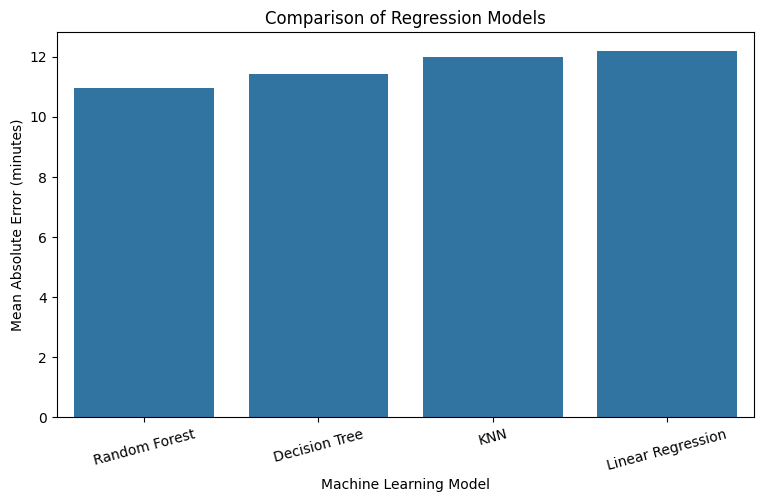

In [ ]:
plt.figure(figsize=(9, 5))

sns.barplot(
    data=results_df,
    x="Model",
    y="MAE"
)

plt.title("Comparison of Regression Models")
plt.xlabel("Machine Learning Model")
plt.ylabel("Mean Absolute Error (minutes)")
plt.xticks(rotation=15)

plt.show()


## 14. Hyperparameter Tuning

After the initial comparison, Random Forest is tuned using `GridSearchCV`. The grid tests different values for the number of trees, maximum tree depth, and minimum samples per leaf.

We use TimeSeriesSplit because our hospital data is time-dependent. It divides the data chronologically, using earlier records for training and later records for validation. With three splits, it evaluates the model across three different time periods and helps us select better hyperparameters without randomly mixing past and future data..

In [ ]:
# Tune Random Forest hyperparameters using time-series cross-validation.
from sklearn.model_selection import GridSearchCV, TimeSeriesSplit

rf_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("regressor", RandomForestRegressor(
        random_state=42,
        n_jobs=-1
    ))
])

parameters = {
    "regressor__n_estimators": [100, 150],
    "regressor__max_depth": [10, 15, 20],
    "regressor__min_samples_leaf": [1, 2]
}

time_cv = TimeSeriesSplit(n_splits=3)

grid = GridSearchCV(
    estimator=rf_pipeline,
    param_grid=parameters,
    scoring="neg_mean_absolute_error",
    cv=time_cv,
    n_jobs=-1,
    verbose=1
)

grid.fit(xtrain, ytrain)

print("Best Parameters:", grid.best_params_)

print("Best CV MAE:", -grid.best_score_)

Fitting 3 folds for each of 12 candidates, totalling 36 fits
Best Parameters: {'regressor__max_depth': 10, 'regressor__min_samples_leaf': 2, 'regressor__n_estimators': 150}
Best CV MAE: 10.921146984485567


## 15. Final Model Evaluation

The best estimator selected by grid search is used to make predictions on the held-out test set. MAE, RMSE, and R² are reported again to evaluate the tuned Random Forest model on data that was not used for fitting or cross-validation.

In [ ]:
# Select the best tuned model and evaluate it on the test set.
best_model = grid.best_estimator_

final_pred = best_model.predict(xtest)

print("Final Model: Tuned Random Forest")

print("MAE:",
      mean_absolute_error(ytest, final_pred))

print("RMSE:",
      np.sqrt(mean_squared_error(ytest, final_pred)))

print("R2 Score:",
      r2_score(ytest, final_pred))

Final Model: Tuned Random Forest
MAE: 10.870240413327657
RMSE: 16.80330568986949
R2 Score: 0.44400113729500656


### Actual vs. Predicted Waiting Time

The scatter plot compares actual waiting times with the model's predictions. Points closer to an imaginary 45-degree diagonal represent more accurate predictions. A wide spread indicates larger prediction errors.

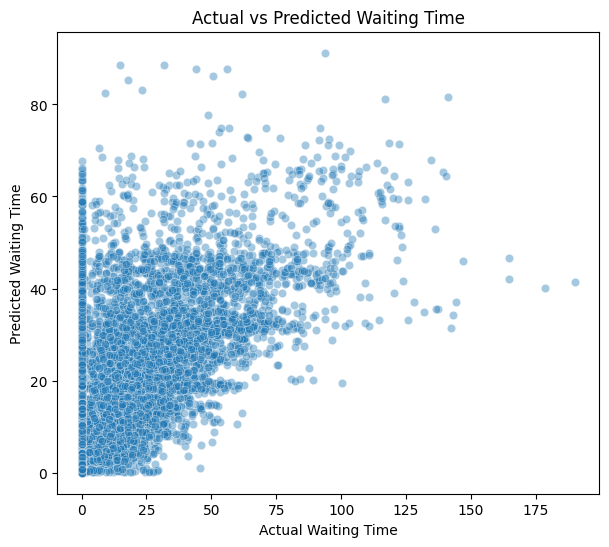

In [ ]:
plt.figure(figsize=(7, 6))

sns.scatterplot(
    x=ytest,
    y=final_pred,
    alpha=0.4
)

plt.xlabel("Actual Waiting Time")
plt.ylabel("Predicted Waiting Time")

plt.title("Actual vs Predicted Waiting Time")

plt.show()

## 16. Feature Importance

Random Forest provides feature-importance values that indicate how much each input feature contributes to reducing prediction error across the trees. The values are sorted so the most important features can be inspected first. Feature importance describes model reliance, not proof of cause and effect.

In [ ]:
# Extract feature names and Random Forest feature-importance scores.
feature_names = (
    best_model
    .named_steps["preprocessor"]
    .get_feature_names_out()
)

importance = (
    best_model
    .named_steps["regressor"]
    .feature_importances_
)

importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importance
})

importance_df = importance_df.sort_values(
    by="Importance",
    ascending=False
)

display(importance_df.head(15))

,Feature,Importance
13,num__queue_per_doctor,0.714944
4,num__queue_length_at_arrival,0.041096
7,num__patients_arrived_last_30min,0.033472
11,num__arrival_day,0.029163
5,num__available_doctors,0.026071
2,num__hour_of_day,0.023643
10,num__arrival_hour,0.022722
0,num__patient_age,0.020520
8,num__average_service_time_min,0.019699
12,num__arrival_dayofweek,0.016196


### Top 15 Features

The bar chart visualizes the 15 features with the highest importance scores. This helps explain which input variables the trained Random Forest relied on most when making predictions.

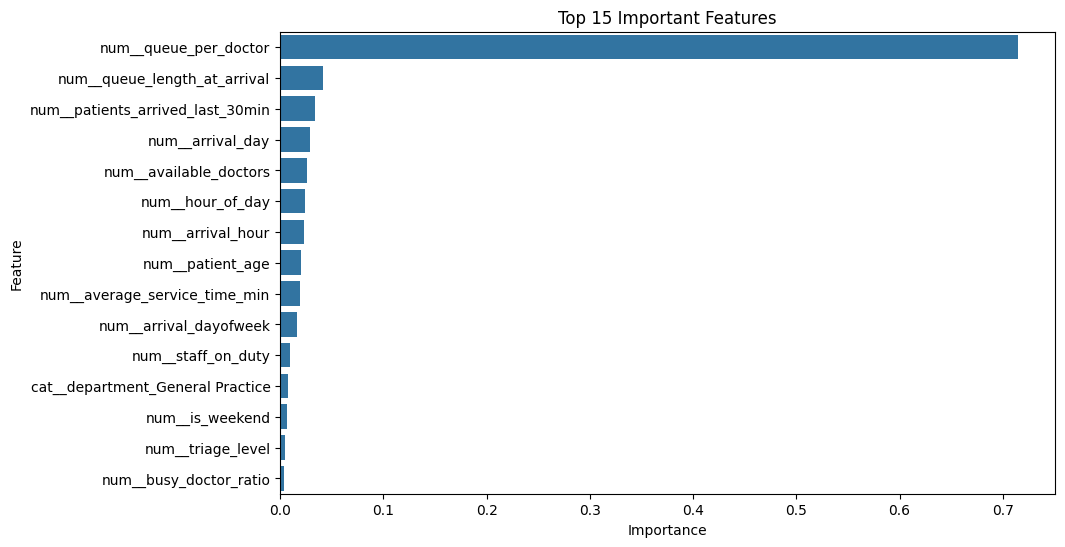

In [ ]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=importance_df.head(15),
    x="Importance",
    y="Feature"
)

plt.title("Top 15 Important Features")

plt.show()

## 17. Preparing a New Patient Example

The feature names are displayed to check the expected input columns. A sample patient record is then created using the same feature structure as the training data. The example values are illustrative and are not a real patient's personal information.

In [ ]:
# Create one illustrative new patient record for prediction.
new_patient = pd.DataFrame([{
    'department': 'Cardiology',
    'service_type': 'Consultation',
    'patient_age': 45,
    'triage_level': 3,
    'day_of_week': 'Wednesday',
    'hour_of_day': 10,
    'is_weekend': 0,
    'queue_length_at_arrival': 15,
    'available_doctors': 5,
    'staff_on_duty': 8,
    'patients_arrived_last_30min': 10,
    'average_service_time_min': 15,
    'doctors_currently_busy': 3,
    'hospital_load_level': 'Medium',
    'arrival_hour': 10,
    'arrival_day': 19,
    'arrival_dayofweek': 2,
    'queue_per_doctor': 3.0,
    'busy_doctor_ratio': 0.375
}])

queue_per_doctor = 15 / 5


busy_doctor_ratio = 3 / 8



A patient arrives at the hospital with a queue length of 15, five available doctors, and three doctors currently busy. The model estimates the patient's waiting time based on the conditions at arrival.

In [ ]:
# Predict the waiting time for the sample patient.
prediction = best_model.predict(new_patient)

print(f"Predicted Waiting Time: {prediction[0]:.2f} minutes")

Predicted Waiting Time: 4.06 minutes


# Conclusion

This project demonstrates how Machine Learning can be applied to a real-world healthcare problem by predicting hospital patient waiting times. By analysing factors related to patient arrivals, queue length, and doctor availability, the system aims to provide useful waiting-time estimates. It can support hospitals in improving queue management and making the patient experience more convenient.

### Key Highlights

- **Model Development:** Compared multiple regression algorithms and selected Random Forest for further optimization.

- **Performance Evaluation:** Used MAE, RMSE, and R² score to evaluate how accurately the model predicts waiting times.

- **Practical Benefits:** Helps hospitals estimate waiting times, manage patient queues, and plan available resources more effectively.

- **Future Scope:** Integrating real-time hospital data and developing a user-friendly application could make the system more useful in actual hospital environments.

**Our Goal:** Using Machine Learning to make hospital services more efficient and patient-friendly.